# 10 Kenya to Ghana transfer (Part C)

NkwaPay wants to launch in Ghana with a model trained only on Kenyan loans. There are **no Ghanaian labels**, so we cannot measure Ghana accuracy directly. Instead we ask: how different are Ghanaian applications, does the model have any evidence where Ghana needs it, can reweighting help, and what must NkwaPay collect before trusting Ghana scores?

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from src.config import set_seed, FIGURES, DATA_PROCESSED, SEED
from src import models as M
from src.costs import LoanEconomics
set_seed()
econ = LoanEconomics()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
feat["domain"] = np.select([feat.country_id == "Ghana", feat.split == "train"], ["Ghana test", "Kenya train"], "Kenya test")
ke_tr, gh = feat[feat.domain == "Kenya train"], feat[feat.domain == "Ghana test"]
feat.domain.value_counts()

domain
Kenya train    66520
Kenya test     14983
Ghana test      2084
Name: count, dtype: int64

## 10.1 Side-by-side comparison

In [2]:
summary = feat.groupby("domain").agg(
    loans=("Total_Amount", "size"), median_amount=("Total_Amount", "median"),
    mean_term=("duration", "mean"), share_over_30_days=("duration", lambda s: (s > 30).mean()),
    median_prev_loans=("n_prev_loans", "median"), share_no_history=("n_prev_loans", lambda s: (s == 0).mean()),
    share_new_label=("is_new", "mean"), share_cofunded=("n_lenders", lambda s: (s == 2).mean()),
    mean_lender_share=("Lender_portion_Funded", "mean"),
    first=("disbursement_date", "min"), last=("disbursement_date", "max")).T
summary

domain,Ghana test,Kenya test,Kenya train
loans,2084,14983,66520
median_amount,3051.96,5129.0,5165.5
mean_term,37.452495,8.230194,8.225992
share_over_30_days,0.144434,0.009611,0.009621
median_prev_loans,4.0,9.0,9.0
share_no_history,0.214012,0.090503,0.090454
share_new_label,0.013916,0.006407,0.006524
share_cofunded,0.65691,0.00574,0.032081
mean_lender_share,0.265022,0.220138,0.225694
first,2021-11-30 00:00:00,2021-11-08 00:00:00,2021-10-04 00:00:00


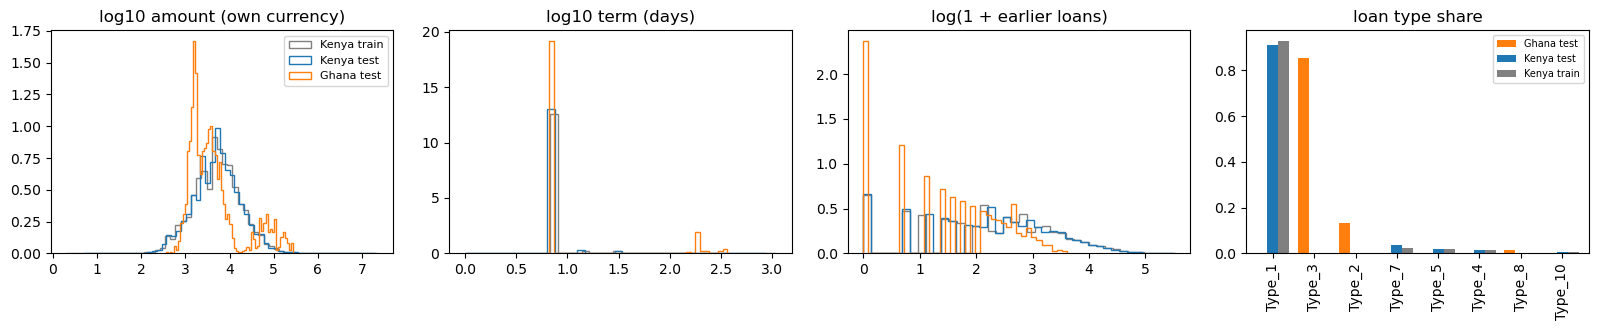

never seen  seen in Kenya
loan_type Type_2           0            274
          Type_3        1782              0
          Type_8          28              0
lender_id 245684           0             84
          296540          80              0
          296542        1802              0
          297182         111              0
          297183           7              0

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
colors = {"Kenya train": "0.5", "Kenya test": "tab:blue", "Ghana test": "tab:orange"}
for dname, c in colors.items():
    d = feat[feat.domain == dname]
    axes[0].hist(np.log10(d.Total_Amount), bins=60, density=True, histtype="step", lw=1.5, color=c, label=dname)
    axes[1].hist(np.log10(d.duration), bins=40, density=True, histtype="step", lw=1.5, color=c)
    axes[2].hist(np.log1p(d.n_prev_loans), bins=40, density=True, histtype="step", lw=1.5, color=c)
axes[0].set(title="log10 amount (own currency)"); axes[1].set(title="log10 term (days)"); axes[2].set(title="log(1 + earlier loans)")
axes[0].legend(fontsize=8)
types = pd.crosstab(feat.loan_type, feat.domain, normalize="columns")
top = types.loc[types.max(axis=1).sort_values(ascending=False).index[:8]]
top.plot.bar(ax=axes[3], color=[colors[c] for c in top.columns], width=0.8); axes[3].set(title="loan type share", xlabel=""); axes[3].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGURES / "10_distributions.png", dpi=200); plt.show()
pd.concat({"loan_type": pd.crosstab(gh.loan_type, gh.loan_type.isin(ke_tr.loan_type).map({True: "seen in Kenya", False: "never seen"})),
           "lender_id": pd.crosstab(gh.lender_id, gh.lender_id.isin(ke_tr.lender_id).map({True: "seen in Kenya", False: "never seen"}))}).fillna(0).astype(int)

**What differs.**
- **Products and lenders.** 87% of Ghana loans are on product types never seen in Kenya (Type_3, Type_8), and 96% are funded by lenders never seen in Kenya. The only seen type, Type_2, had 74 Kenyan loans with a 61% default rate.
- **Terms.** The median Ghana term is still 7 days (Type_3), but about 14% run 150 to 365 days, a range where Kenya has only a few dozen loans.
- **Structure.** Two thirds of Ghana loans are co-funded by two lenders, against 3% in Kenya; that alone nearly identifies a Ghana loan.
- **History.** Ghana borrowers have fewer earlier loans (median 4 against 9), and 21% have none.
- **Currency.** Amounts are in each country's currency (the data dictionary does not say so explicitly; Ghana's medians are consistent with cedis). Any amount-based feature compares cedis with shillings unless converted; at 2023 rates 1 GHS ≈ 12.7 KES.
- **Time.** Ghana loans run Nov 2021 to Mar 2023, inside the Kenyan training window, so this is a **market** shift rather than a time shift.

## 10.2 Domain classifier

If a classifier can tell Kenyan from Ghanaian rows, the two distributions differ in ways the credit model will see. We train LightGBM to predict "is Ghana" with customer-grouped 5-fold CV, first on every deployed input, then without product and lender, then one feature at a time.

In [4]:
dom = feat[feat.domain != "Kenya test"].reset_index(drop=True)
yd = (dom.domain == "Ghana test").astype(int).to_numpy()
cv = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(dom, yd, dom.customer_id))

def domain_auc(model, cols):
    oof = np.zeros(len(dom))
    for a, b in cv:
        oof[b] = clone(model).fit(dom[cols].iloc[a], yd[a]).predict_proba(dom[cols].iloc[b])[:, 1]
    return roc_auc_score(yd, oof), oof

num = M.DEPLOY_FEATURES
auc_all, oof_all = domain_auc(M.lgbm(numeric=num), M.inputs(num))
auc_num, _ = domain_auc(M.lgbm(numeric=num).set_params(prep__cat="drop"), M.inputs(num))
no_struct = [c for c in num if c not in ("n_lenders", "Lender_portion_Funded")]
auc_ns, _ = domain_auc(M.lgbm(numeric=no_struct).set_params(prep__cat="drop"), M.inputs(no_struct))
print(f"Domain AUC, all deployed inputs:                       {auc_all:.4f}")
print(f"Domain AUC, without product and lender:                {auc_num:.4f}")
print(f"Domain AUC, also without co-funding and lender share:  {auc_ns:.4f}")
single = pd.Series({c: roc_auc_score(yd, dom[c].fillna(dom[c].median())) for c in num}).map(lambda a: max(a, 1 - a))
single.sort_values(ascending=False).head(10).round(3).to_frame("single-feature domain AUC")

Domain AUC, all deployed inputs:                       1.0000
Domain AUC, without product and lender:                1.0000
Domain AUC, also without co-funding and lender share:  0.9994


,single-feature domain AUC
has_resolved_history,0.914
n_prev_resolved,0.914
prev_default_rate,0.829
n_lenders,0.821
n_active_loans,0.781
active_amount_log,0.780
days_since_last_loan,0.778
prev_amount_max_log,0.751
prev_amount_mean_log,0.688
amount_per_day_log,0.685


The domain classifier separates the countries essentially perfectly (AUC 1.000, and 0.999 even without product, lender and co-funding).

**One separator is an artefact of the data split.** The best single feature is `has_resolved_history` (AUC 0.91). Ghanaian borrowers do have earlier loans (median 4), but every one of them is an unlabelled Test loan, so `n_prev_resolved`, `n_prev_defaults` and `prev_default_rate` treat their outcomes as unknown and Ghana applicants look like borrowers with no repayment record. In production NkwaPay would know those outcomes, so this part of the shift would disappear. It still affects every Ghana score computed here, and is one more reason those scores cannot be trusted.

Beyond that artefact, the shift is real. Every Ghanaian application lies in a region of feature space the Kenyan model has seen rarely or never. This is **covariate shift** at its most severe, and it comes on top of possible **concept shift** (the same features meaning different risk in Ghana), which unlabelled data cannot detect at all.

## 10.3 Importance weighting (optional)

Under pure covariate shift, reweighting Kenyan training loans by $w(x) = P(\text{Ghana} \mid x) / P(\text{Kenya} \mid x)$ makes the training set resemble Ghana. It only works if the weights are not dominated by a handful of loans. We estimate weights with a regularised logistic domain model (smoother than trees) and measure the **effective sample size**, ESS = (Σw)² / Σw².

In [5]:
dom_lr = M.logreg(numeric=num, class_weight=None, C=0.1)
p_gh = np.zeros(len(dom))
for a, b in cv:
    p_gh[b] = clone(dom_lr).fit(dom[M.inputs(num)].iloc[a], yd[a]).predict_proba(dom[M.inputs(num)].iloc[b])[:, 1]
is_ke = yd == 0
prior = yd.mean() / (1 - yd.mean())
w = (p_gh[is_ke] / (1 - p_gh[is_ke])) / prior
w = np.clip(w, 0, np.quantile(w, 0.999))
ess = w.sum() ** 2 / (w ** 2).sum()
print(f"Logistic domain AUC: {roc_auc_score(yd, p_gh):.4f}")
print(f"Kenyan training loans: {is_ke.sum():,}; effective sample size after weighting: {ess:,.0f} ({ess / is_ke.sum():.2%})")
top_share = np.sort(w)[::-1]
print(f"Top 1% of Kenyan loans carry {top_share[: int(len(w) * .01)].sum() / w.sum():.1%} of the total weight")
kw = dom[is_ke].assign(w=w)
heavy = kw.nlargest(int(len(kw) * .01), "w")
print(f"Defaults among the heaviest 1% of Kenyan loans: {int(heavy.target.sum())} of {len(heavy)}")
heavy.loan_type.value_counts().head(5).to_frame("heaviest 1% by loan type")

Logistic domain AUC: 1.0000
Kenyan training loans: 66,520; effective sample size after weighting: 1,515 (2.28%)
Top 1% of Kenyan loans carry 49.9% of the total weight
Defaults among the heaviest 1% of Kenyan loans: 152 of 665


,heaviest 1% by loan type
loan_type,
Type_4,167
Type_5,144
Type_2,67
Type_14,65
Type_7,60


In [6]:
ke_rows = dom[is_ke]
base = M.logreg(numeric=num, class_weight=None).fit(ke_rows[M.inputs(num)], ke_rows.target)
wtd = M.logreg(numeric=num, class_weight=None).fit(ke_rows[M.inputs(num)], ke_rows.target, model__sample_weight=w)
gh_X = gh[M.inputs(num)]
cmp = pd.DataFrame({"unweighted": base.predict_proba(gh_X)[:, 1], "importance-weighted": wtd.predict_proba(gh_X)[:, 1]})
pd.DataFrame({"mean P(default) on Ghana": cmp.mean(), "share declined at 0.062": (cmp > econ.threshold).mean(),
              "Spearman with unweighted": cmp.corr(method="spearman").iloc[0]}).round(3)

,mean P(default) on Ghana,share declined at 0.062,Spearman with unweighted
unweighted,0.136,0.217,1.000
importance-weighted,0.127,0.145,0.576


**Reading.** The weights collapse onto a small set of Kenyan loans (the few long-term, co-funded, non-Type_1 loans that look Ghanaian), so the effective sample shrinks to a small fraction of the data and those loans carry the defaults. The weighted model changes Ghana scores substantially, which shows how fragile they are, but **we cannot tell whether it is better**, because no Ghanaian outcomes exist to check it. Importance weighting also assumes the feature-to-risk relationship is the same in both countries, the very thing that is most in doubt (new products, new lenders, a different regulator and currency). We do not use it for the deployed model; it is a sensitivity analysis.

## 10.4 What the Kenyan model says about Ghana

In [7]:
dep = M.logreg(numeric=num, class_weight=None).fit(ke_tr[M.inputs(num)], ke_tr.target)
gh = gh.assign(p=dep.predict_proba(gh[M.inputs(num)])[:, 1])
ke_te = feat[feat.domain == "Kenya test"].assign(p=lambda d: dep.predict_proba(d[M.inputs(num)])[:, 1])
by = gh.groupby("loan_type").agg(loans=("p", "size"), mean_p=("p", "mean"), declined=("p", lambda s: (s > econ.threshold).mean()))
by.loc["ALL GHANA"] = [len(gh), gh.p.mean(), (gh.p > econ.threshold).mean()]
by.loc["Kenya test (reference)"] = [len(ke_te), ke_te.p.mean(), (ke_te.p > econ.threshold).mean()]
by.round(3)

,loans,mean_p,declined
loan_type,,,
Type_2,274.0,0.669,0.996
Type_3,1782.0,0.044,0.085
Type_8,28.0,0.740,1.000
ALL GHANA,2084.0,0.136,0.217
Kenya test (reference),14983.0,0.018,0.067


The model would decline 22% of Ghana applicants, three times the Kenyan rate. The split by product is stark: **almost every Type_2 and Type_8 loan is declined** (long, large loans; Type_2 defaulted 61% of the time in Kenya), while Type_3, the 7-day product that makes up 86% of Ghana volume, is declined at 8.5%, close to Kenya. For Type_3 and Type_8 the model has no product information at all, so their scores rest on term, history and co-funding, which are themselves out of range or distorted by the artefact above. These numbers describe the model's extrapolation, not Ghana's risk.

## 10.5 Evidence NkwaPay needs before trusting Ghana scores

| # | Evidence | Why | How |
|---|---|---|---|
| 1 | **Ghanaian repayment outcomes** for a pilot cohort | Without labels neither accuracy nor calibration can be measured, and concept shift is invisible | Lend small, capped amounts to a random or lightly screened pilot group; observe outcomes for at least one full term of the longest product |
| 2 | **Calibration on Ghana outcomes** | Kenyan probabilities were already over-spread after Dec 2022 (Section 5); Ghana will be worse | Platt or isotonic recalibration on pilot outcomes, then monitor predicted vs observed by score band monthly |
| 3 | **Product and lender definitions** for Type_3, Type_8 and the four new lenders | 96% of Ghana loans fall in `Unknown` categories | Map Ghana products to Kenyan analogues (term, pricing, collateral) or treat them as new and learn from pilot data |
| 4 | **Full repayment history for Ghanaian borrowers** | Here their earlier outcomes are unknown (Test split), which makes every applicant look record-less | Build history features from NkwaPay's own Ghana ledger, not from the competition split |
| 5 | **Currency-consistent amounts** | Amount features compare cedis with shillings | Convert to a common unit (USD at disbursement date) or use within-country relative size |
| 6 | **Ghana credit bureau data** | Act 726 (s.26, as reported) requires a credit report before lending; thin-file borrowers dominate | Integrate a licensed bureau (e.g. under the Credit Reporting Regulations 2020) as a feature and a compliance step |
| 7 | **Out-of-time validation in Ghana** | The Kenyan data showed a regime change can halve performance | Hold out the latest pilot months; repeat the Section 4 temporal check |
| 8 | **Fairness checks on Ghanaian groups** | Thin-file and new borrowers are where both the model and Ghana's under-served population sit (Part D) | Section 11 metrics by segment on pilot outcomes |
| 9 | **Monitoring triggers** | Domain AUC near 1.0 means drift alarms must be live from day one | Track domain-classifier score, approval rate, default rate and mean prediction weekly; predefined thresholds for review |

**Recommendation.** Do **not** use the Kenyan model to make automated approve/decline decisions in Ghana at launch. Use it, at most, as one input to a conservative, capped pilot with human review, while collecting the evidence above; retrain or recalibrate once Ghanaian outcomes exist.